# Hands-On Task — Association Rule Mining (Lecture 6)

**Course:** INFO 4670  
**Focus:** Support, Confidence, Apriori, FP-Growth  

Run cells top-to-bottom. Fill short answers where prompted.


Setup → Toy Data Preprocessing → Apriori → Association Rule Generation → FP-Growth → Real Data Preprocessing → Real Data Rule Generation → Visualization (Optional). 

## 0) Setup
If a package is missing locally, uncomment the `%pip install` lines and run once.

In [5]:
%pip install pandas mlxtend matplotlib networkx

/usr/lib/python3.14/pty.py:66: DeprecationWarning: This process (pid=96011) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


In [6]:
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


## 1) Load a Small Transaction Dataset (Toy)
We start with a tiny dataset to make outputs easy to read.

In [7]:
# Toy dataset with 5 transactions
transactions = [
    ["Milk", "Bread", "Butter"],
    ["Milk", "Bread"],
    ["Bread", "Butter"],
    ["Milk", "Bread", "Eggs"],
    ["Milk", "Eggs"]
]

pd.DataFrame({"TID": [f"T{i+1}" for i in range(len(transactions))],
              "Items": [", ".join(t) for t in transactions]})


,TID,Items
0,T1,"Milk, Bread, Butter"
1,T2,"Milk, Bread"
2,T3,"Bread, Butter"
3,T4,"Milk, Bread, Eggs"
4,T5,"Milk, Eggs"


**Q1.** How many transactions are there?  
Answer: `5`


## 2) Convert to One-Hot Encoding

In [8]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
oht = pd.DataFrame(te_ary, columns=te.columns_).astype(bool)
oht.head()


,Bread,Butter,Eggs,Milk
0,True,True,False,True
1,True,False,False,True
2,True,True,False,False
3,True,False,True,True
4,False,False,True,True


**Q2.** What does `True`/`1` mean in this matrix?  
Answer: `It means if the matrix shows a true or 1 it means it corresponds to the items being purchased or not `


## 3) Frequent Itemsets with Apriori (min_support = 0.4)

In [13]:
freq_ap = apriori(oht, min_support=0.1, use_colnames=True)
freq_ap.sort_values('support', ascending=False)


,support,itemsets
0,0.8,frozenset({Bread})
3,0.8,frozenset({Milk})
6,0.6,"frozenset({Bread, Milk})"
2,0.4,frozenset({Eggs})
1,0.4,frozenset({Butter})
4,0.4,"frozenset({Butter, Bread})"
8,0.4,"frozenset({Eggs, Milk})"
5,0.2,"frozenset({Eggs, Bread})"
7,0.2,"frozenset({Butter, Milk})"
9,0.2,"frozenset({Butter, Bread, Milk})"


**Q3.** Write down the top 3 frequent itemsets from the table above.  
Answer: `bread, milk, and both bread and milk in the same transaction`


## 4) Association Rules (metric = confidence, min_threshold = 0.6)

In [10]:
rules_ap = association_rules(freq_ap, metric='confidence', min_threshold=0.6)
rules_ap[['antecedents','consequents','support','confidence','lift']].sort_values('confidence', ascending=False)


,antecedents,consequents,support,confidence,lift
0,frozenset({Butter}),frozenset({Bread}),0.4,1.00,1.2500
3,frozenset({Eggs}),frozenset({Milk}),0.4,1.00,1.2500
1,frozenset({Bread}),frozenset({Milk}),0.6,0.75,0.9375
2,frozenset({Milk}),frozenset({Bread}),0.6,0.75,0.9375


**Q4.** Pick one rule and explain in your own words (1–2 sentences).  
Example: `{Milk} ⇒ {Bread}` …  
Answer: `With the {Milk} -> {Bread} it shows the support of .6 and with cofidence of .75 and a lift of .9375. This suggests that 75% of the time when milk is bought, bread was also bought. This can help busniesses maybe thinking of giving discounts when bought together. `


## 5) FP-Growth Comparison (min_support = 0.4)

In [11]:
freq_fp = fpgrowth(oht, min_support=0.4, use_colnames=True)
rules_fp = association_rules(freq_fp, metric='confidence', min_threshold=0.6)
rules_fp[['antecedents','consequents','support','confidence','lift']].sort_values('confidence', ascending=False)


,antecedents,consequents,support,confidence,lift
3,frozenset({Eggs}),frozenset({Milk}),0.4,1.00,1.2500
2,frozenset({Butter}),frozenset({Bread}),0.4,1.00,1.2500
1,frozenset({Milk}),frozenset({Bread}),0.6,0.75,0.9375
0,frozenset({Bread}),frozenset({Milk}),0.6,0.75,0.9375


**Q5.** Do Apriori and FP-Growth produce the same rules on this toy set? Why or why not?  
Answer: `Yes it will produce the same set of rules because both algorithms will use the same critera.`


## 6) Real Dataset Mini-Demo — `bread_basket.csv`
We will use only the **first 200 transactions** in class for speed. Place `bread_basket.csv` next to this notebook or edit the path.

In [14]:
CSV_PATH = "bread_basket-2.csv"  # update if needed
bread = pd.read_csv(CSV_PATH)

# Build a list of items per transaction (subset first N transactions)
N = 200
basket = (bread.groupby('transaction')['item'].apply(list)
                 .reset_index()
                 .sort_values('transaction')
                 .head(N)['item']
                 .tolist())

# One-hot encode
te_b = TransactionEncoder()
oht_b = pd.DataFrame(te_b.fit(basket).transform(basket), columns=te_b.columns_).astype(bool)
oht_b.shape


(200, 30)

In [17]:
# Frequent itemsets and rules (adjust thresholds to show a few rules)
minsup = 0.01   # 5%
minconf = 0.3   # 30%

freq_b = fpgrowth(oht_b, min_support=minsup, use_colnames=True)
rules_b = association_rules(freq_b, metric='confidence', min_threshold=minconf)
rules_b[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False).head(15)


,antecedents,consequents,support,confidence,lift
19,frozenset({Mineral water}),frozenset({Hearty & Seasonal}),0.015,0.500000,9.090909
18,frozenset({Tartine}),"frozenset({Coffee, Tea})",0.015,0.500000,7.692308
2,frozenset({Hot chocolate}),frozenset({Cookies}),0.010,0.400000,6.666667
29,frozenset({Frittata}),frozenset({Hearty & Seasonal}),0.010,0.333333,6.060606
35,frozenset({Soup}),frozenset({Hearty & Seasonal}),0.015,0.333333,6.060606
33,frozenset({Frittata}),"frozenset({Coffee, Tea})",0.010,0.333333,5.128205
26,frozenset({Victorian Sponge}),frozenset({Tea}),0.015,0.750000,3.947368
16,"frozenset({Tartine, Coffee})",frozenset({Tea}),0.015,0.600000,3.157895
24,"frozenset({Juice, Coffee})",frozenset({Pastry}),0.010,0.333333,2.898551
8,frozenset({Medialuna}),frozenset({Pastry}),0.020,0.307692,2.675585


**Q6.** Pick one rule from the table above that you find interesting. Why?  
Answer: `Tartine, tea and coffee only becuase it shows that with certianty that when tartine and tea are bought 100% certainty coffee is picked up too. Maybe there is a common trend in the area that all people buy the same items. `


## 7) (Optional) Visualize a Small Rule Subgraph
Filter to rules among `{Bread, Coffee, Cake, Tea}` and draw a small directed graph.

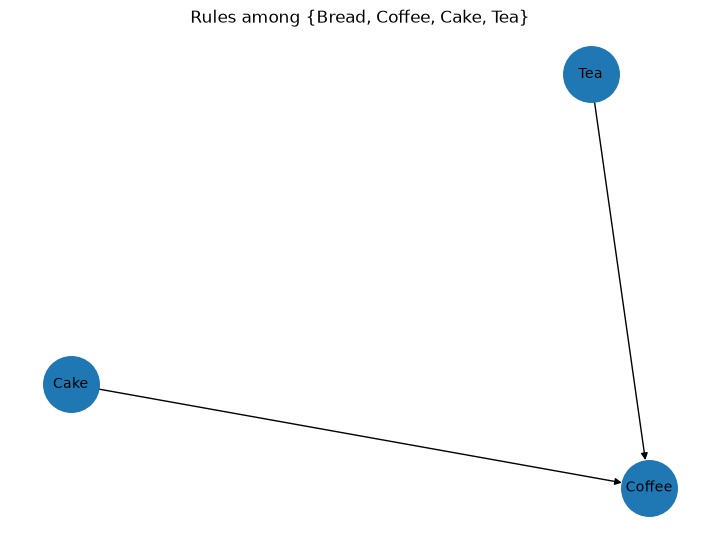

In [18]:
import networkx as nx

focus = {'Bread','Coffee','Cake','Tea'}
sub = rules_b[
    rules_b['antecedents'].apply(lambda s: s.issubset(focus)) &
    rules_b['consequents'].apply(lambda s: s.issubset(focus))
].copy()

G = nx.DiGraph()
for _, r in sub.iterrows():
    a = ','.join(sorted(list(r['antecedents'])))
    c = ','.join(sorted(list(r['consequents'])))
    G.add_edge(a, c, weight=float(r['confidence']), lift=float(r['lift']))

plt.figure(figsize=(7,5))
pos = nx.spring_layout(G, seed=0)
nx.draw(G, pos, with_labels=True, node_size=1600, font_size=10, arrows=True)
plt.title("Rules among {Bread, Coffee, Cake, Tea}")
plt.show()


## 8) Wrap-up
- Difference between **Apriori** and **FP-Growth** in one sentence:  
  Answer: `Apriori generates itemsets abd scans databases but F-P Growth builds a FP-Tree to effeciencly find single item that are frequent.`
- Why do we need **lift** in addition to support & confidence?  
  Answer: `Lift helps find the stength of assosciation between the items. While confidence is the probability that something happening in a scenario`
